# Housing in Buenos Aires: Feature Engineering & Ridge Regression Pipeline

**Author:** Jeremy Oche Okoh (`U24DS1007`)  
**Programme:** B.Sc. Data Science, Philomath University, Maitama – Abuja  
**Course:** DTS 299 (SIWES) — SBTS Group Nigeria (Development Department)  

---

### Project Overview
This notebook builds an end-to-end predictive pricing pipeline for Capital Federal apartments in Buenos Aires across five raw real-estate CSV files:

1. **Environment Setup** — Importing libraries for automated multi-file ingestion, visualization, regularized regression, and interactive deployment.
2. **Modular Data Wrangling & Feature Hygiene** — Consolidating five CSVs via `glob` and a reusable `wrangle()` function (subsetting Capital Federal apartments `< $400,000`, trimming 10th–90th percentile area outliers, removing >50% null columns, preventing target leakage, and dropping collinear size features) to produce **6,582 clean records across 57 neighbourhoods**.
3. **Exploratory Diagnostics & Split** — Verifying cardinality and confirming low multicollinearity among numeric predictors (`surface_covered_in_m2`, `lat`, `lon`).
4. **Ridge Regression Pipeline & Evaluation** — Benchmarking against a naive mean baseline (`$44,860.11` MAE), fitting `OneHotEncoder → SimpleImputer → Ridge()`, lowering MAE to **`$24,207.11` (46.04% reduction)**, and running inference on unseen test features.
5. **Interactive Valuation Tool & Summary** — Wrapping the pipeline in `make_prediction()` with `ipywidgets` controls for live apartment valuation.


---
## 1. Environment Setup

Only active libraries required by the pipeline and interactive widget are imported below.


In [1]:
import warnings
from glob import glob

import pandas as pd
import seaborn as sns
from category_encoders import OneHotEncoder
from ipywidgets import Dropdown, FloatSlider, IntSlider, interact
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline

warnings.simplefilter(action="ignore", category=UserWarning)


---
## 2. Data Preparation & Feature Hygiene

We encapsulate all subsetting, outlier trimming, string parsing, leakage removal, and collinearity pruning inside a single `wrangle(filepath)` function so all five source CSVs are processed identically.


In [2]:
def wrangle(filepath):
    # Read CSV file
    df = pd.read_csv(filepath)

    # Subset data: Apartments in "Capital Federal", less than 400,000
    mask_ba = df["place_with_parent_names"].str.contains("Capital Federal")
    mask_apt = df["property_type"] == "apartment"
    mask_price = df["price_aprox_usd"] < 400_000
    df = df[mask_ba & mask_apt & mask_price]

    # Subset data: Remove outliers for "surface_covered_in_m2"
    low, high = df["surface_covered_in_m2"].quantile([0.1, 0.9])
    mask_area = df["surface_covered_in_m2"].between(low, high)
    df = df[mask_area]

    # Split "lat-lon" column
    df[["lat", "lon"]] = df["lat-lon"].str.split(",", expand=True).astype(float)
    df.drop(columns="lat-lon", inplace=True)

    # Get place name
    df["neighborhood"] = df["place_with_parent_names"].str.split("|", expand=True)[3]
    df.drop(columns="place_with_parent_names", inplace=True)

    #drop predominantly null columns
    df.drop(columns=['floor','expenses'],inplace=True)

    #drop high-cardinality and low-cardinality columns
    df.drop(columns=['operation','property_type','currency','properati_url'],inplace=True)

    #drop leaky columns
    df.drop(columns=['price','price_aprox_local_currency','price_usd_per_m2','price_per_m2'],inplace=True)

    #drop highly correlated columns
    df.drop(columns=['rooms','surface_total_in_m2'],inplace=True)
    
    return df

In [3]:
files = sorted(glob("data/buenos-aires-real-estate-*.csv"))
files


['data\\buenos-aires-real-estate-1.csv',
 'data\\buenos-aires-real-estate-2.csv',
 'data\\buenos-aires-real-estate-3.csv',
 'data\\buenos-aires-real-estate-4.csv',
 'data\\buenos-aires-real-estate-5.csv']

In [4]:
frames = [wrangle(file) for file in files]

In [5]:
df = pd.concat(frames, ignore_index=True)
df.info()
df.head()


<class 'pandas.DataFrame'>
RangeIndex: 6582 entries, 0 to 6581
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        6582 non-null   float64
 1   surface_covered_in_m2  6582 non-null   float64
 2   lat                    6316 non-null   float64
 3   lon                    6316 non-null   float64
 4   neighborhood           6582 non-null   str    
dtypes: float64(4), str(1)
memory usage: 257.2 KB


,price_aprox_usd,surface_covered_in_m2,lat,lon,neighborhood
0,129000.0,70.0,-34.584651,-58.454693,Chacarita
1,87000.0,42.0,-34.638979,-58.500115,Villa Luro
2,118000.0,54.0,-34.615847,-58.459957,Caballito
3,57000.0,42.0,-34.625222,-58.382382,Constitución
4,90000.0,50.0,-34.610610,-58.412511,Once


---
## 3. Exploratory Diagnostics & Feature-Target Split

Inspect categorical cardinality (`neighborhood` = 57 levels) and verify that the retained numeric predictors (`surface_covered_in_m2`, `lat`, `lon`) do not suffer from strong linear multicollinearity.


In [6]:
df.select_dtypes(include=["object", "string"]).nunique()


neighborhood    57
dtype: int64

<Axes: >

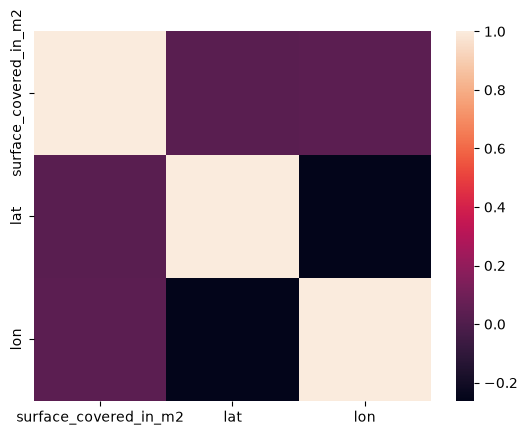

In [7]:
corr = df.select_dtypes("number").drop(columns="price_aprox_usd").corr()
sns.heatmap(corr);


In [8]:
target = "price_aprox_usd"
X_train = df.drop(columns=target)
y_train = df[target]


---
## 4. Model Building & Evaluation

### 4.1 Naive Mean Baseline


In [9]:
y_mean = y_train.mean()
y_pred_baseline = [y_mean] * len(y_train)

print("Mean apt price:", round(y_mean, 2))
print("Baseline MAE:", round(mean_absolute_error(y_train, y_pred_baseline), 2))


Mean apt price: 132383.84
Baseline MAE: 44860.10834274133


### 4.2 Ridge Regression Pipeline
One-hot encoding 57 neighbourhoods introduces 57 binary indicator columns that can destabilize plain OLS. Using `Ridge()` applies L2 regularization to shrink unstable dummy coefficients.


In [10]:
model = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    SimpleImputer(),
    Ridge()
)
model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('onehotencoder', ...), ('simpleimputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['su...m2', 'lat', 'lon', 'ne...od']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,cols,['neighborhood']
,verbose,0
,drop_invariant,False
,return_df,True


### 4.3 Training Evaluation & Unseen Test Inference

In [11]:
y_pred_training = model.predict(X_train)
print("Training MAE:", round(mean_absolute_error(y_train, y_pred_training), 2))


Training MAE: 24207.107190330313


In [12]:
X_test = pd.read_csv("data/buenos-aires-test-features.csv")
y_pred_test = pd.Series(model.predict(X_test))
y_pred_test.head()

0    231122.403569
1    162572.942392
2     68477.949626
3     63521.438989
4    105694.463885
dtype: float64

---
## 5. Interactive Valuation Tool

Wrap the trained pipeline in `make_prediction()` and bind it to `ipywidgets` controls for interactive apartment price estimation.


In [13]:
def make_prediction(area, lat, lon, neighborhood):
    data = {
        "surface_covered_in_m2":area,
        "lat":lat,
        "lon":lon,
        "neighborhood":neighborhood
    }
    df = pd.DataFrame(data,index=[0])
    prediction = model.predict(df).round(2)[0]
    return f"Predicted apartment price: ${prediction}"

In [14]:
make_prediction(110, -34.60, -58.46, "Villa Crespo")

'Predicted apartment price: $250775.11'

In [15]:
interact(
    make_prediction,
    area=IntSlider(
        min=X_train["surface_covered_in_m2"].min(),
        max=X_train["surface_covered_in_m2"].max(),
        value=X_train["surface_covered_in_m2"].mean(),
    ),
    lat=FloatSlider(
        min=X_train["lat"].min(),
        max=X_train["lat"].max(),
        step=0.01,
        value=X_train["lat"].mean(),
    ),
    lon=FloatSlider(
        min=X_train["lon"].min(),
        max=X_train["lon"].max(),
        step=0.01,
        value=X_train["lon"].mean(),
    ),
    neighborhood=Dropdown(options=sorted(X_train["neighborhood"].unique())),
);

interactive(children=(IntSlider(value=53, description='area', max=101, min=30), FloatSlider(value=-34.59890626…

---
## 6. Summary & Model Performance

| Model | Features Used | Mean Absolute Error (USD) | Improvement vs. Baseline |
| :--- | :--- | :---: | :---: |
| **Naive Mean Baseline** | Constant training mean (`$132,383.84`) | `$44,860.11` | Benchmark |
| **Ridge Regression Pipeline** | `surface_covered_in_m2`, `lat`, `lon`, `neighborhood` (57 levels) | **`$24,207.11`** | **46.04% reduction (`-$20,653.00`)** |

### Key Engineering Takeaways
- **Modular wrangling (`wrangle()` + `glob`)** eliminated repetitive manual cleaning across five source CSVs and guaranteed identical schemas.
- **Strict leakage and collinearity audits** removed price-derived columns and redundant size features before model fitting.
- **L2 regularization (`Ridge`)** handled 57 one-hot encoded neighbourhood features cleanly, cutting average prediction error nearly in half while supporting real-time interactive valuations (e.g., `110 m²` in Villa Crespo → `$250,775.11`).
